In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings("ignore")
import plotly.express as px
from sklearn.datasets import make_blobs
%matplotlib inline

In [9]:
X,y = make_blobs(n_samples = 100, centers = 3, n_features = 2, random_state = 23)

In [10]:
X.shape

(100, 2)

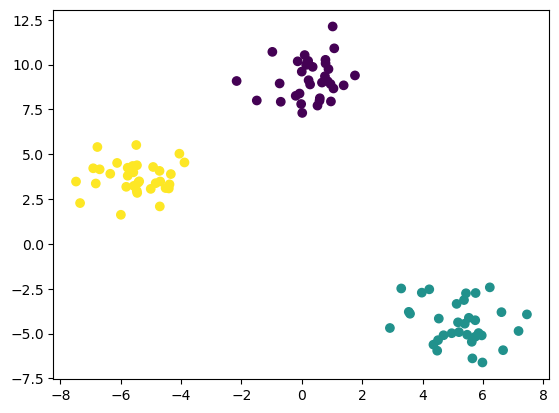

In [13]:
plt.scatter(X[:,0],X[:,1], c=y)

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
 X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.33, random_state=42)

In [17]:
from sklearn.cluster import KMeans

#manual process for Elbow Method to select the K value

In [18]:
wcss = []
for k in range(1,11):
    kmeans = KMeans(n_clusters=k, init='k-means++')
    kmeans.fit(X_train)
    wcss.append(kmeans.inertia_)

In [19]:
wcss

[3605.136759084827,
 832.4313906120431,
 124.19935535709936,
 100.92366316084954,
 91.01733847058625,
 87.05523974419917,
 63.65034741983622,
 52.498713303780676,
 45.38910179156363,
 43.79065940352149]

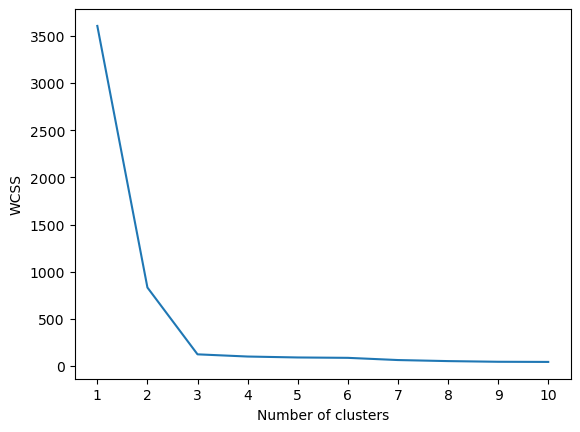

In [22]:
plt.plot(range(1,11),wcss)
plt.xticks(range(1,11))
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.show()

In [26]:
kmeans = KMeans(n_clusters = 3, init="k-means++")

In [30]:
y_labels = kmeans.fit_predict(X_train) 

In [33]:
y_test_label = kmeans.predict(X_test)

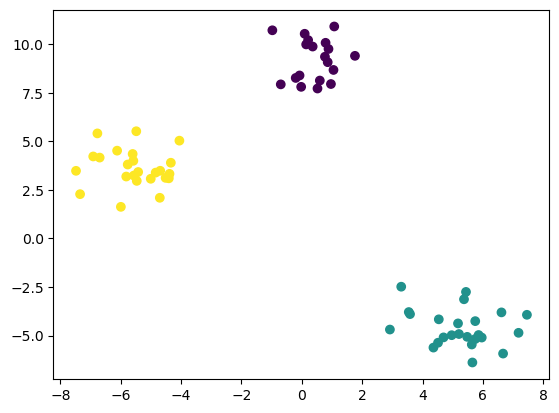

In [31]:
plt.scatter(X_train[:,0],X_train[:,1], c=y_labels)

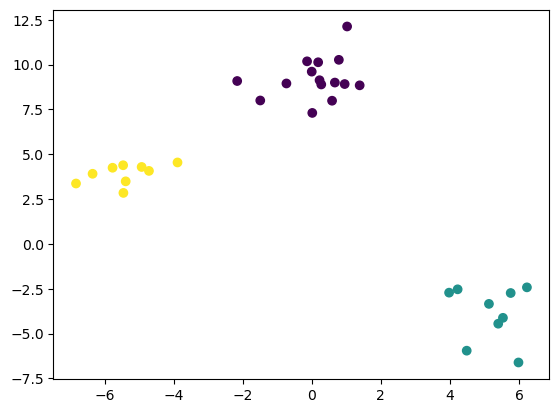

In [34]:
plt.scatter(X_test[:,0],X_test[:,1], c=y_test_label)

In [37]:
## knee locator
!pip install kneed

Defaulting to user installation because normal site-packages is not writeable


In [38]:
 from kneed import KneeLocator

In [39]:
kl = KneeLocator(range(1,11),wcss, curve="convex", direction='decreasing')

In [41]:
print(kl.elbow)

3


In [42]:
## performance

In [43]:
from sklearn.metrics import silhouette_score

In [45]:
silhouette_coefficients = []
for k in range(2,11):
    kmeans = KMeans(n_clusters=k, init='k-means++')
    kmeans.fit(X_train)
    score = silhouette_score(X_train,kmeans.labels_)
    silhouette_coefficients.append(score)

In [46]:
silhouette_coefficients


[0.7221825607415234,
 0.8182367206056518,
 0.7187857321512967,
 0.5579994893767286,
 0.4076474593171824,
 0.33569172392917307,
 0.38821056269932247,
 0.33736737872082945,
 0.40606135090306816]